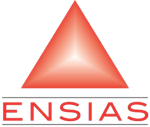

# TP 3 — Régression linéaire

**Module :** Introduction au Machine Learning
**Enseignant :** Prof. Aissam BERRAHOU — ENSIAS, Université Mohammed V de Rabat
**Niveau :** 2e année cycle ingénieur
**Durée estimée :** 2 heures
**Support associé :** Lecture 3 — Régression

## 1. Objectifs pédagogiques

*Ce TP prolonge le cours : vous allez refaire sur machine les calculs vus en séance, puis passer à un vrai jeu de données.*

1. Calculer **à la main** (avec NumPy) les paramètres $\beta_0$ et $\beta_1$ par les moindres carrés.
2. Implémenter la **descente de gradient** et suivre la fonction coût.
3. Évaluer un modèle avec la **MSE** et le **$R^2$**.
4. Utiliser `LinearRegression` de scikit-learn sur un jeu de données réel (Diabetes).
5. Observer le **surapprentissage** avec la régression polynomiale.

## 2. Rappel théorique

*Avant de coder, un rapide rappel des formules dont nous aurons besoin.*

Modèle de régression linéaire simple : $\hat{y} = \beta_0 + \beta_1 x$

**Moindres carrés :**
$$\hat\beta_1 = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sum_i (x_i-\bar x)^2} \qquad \hat\beta_0 = \bar y - \hat\beta_1 \bar x$$

**Fonction coût (erreur quadratique moyenne) :** $L(\beta_0,\beta_1) = \frac{1}{n}\sum_i (\hat y_i - y_i)^2$

**Descente de gradient :** $\beta \leftarrow \beta - \alpha \nabla L$, avec
$\frac{\partial L}{\partial \beta_0} = \frac{2}{n}\sum_i(\hat y_i-y_i)$ et $\frac{\partial L}{\partial \beta_1} = \frac{2}{n}\sum_i(\hat y_i-y_i)\,x_i$

**Évaluation :** $MSE = \frac{1}{n}\sum e_i^2$ et $R^2 = 1 - \frac{SSE}{SST}$, avec $SST=\sum (y_i-\bar y)^2$.

## 3. Import des bibliothèques

*On charge d'abord les outils. Tout le TP n'utilise que NumPy, pandas, Matplotlib et scikit-learn.*

In [1]:
import numpy as np                          # calcul numérique
import pandas as pd                         # tableaux
import matplotlib.pyplot as plt             # graphiques

from sklearn.linear_model import LinearRegression        # régression linéaire
from sklearn.datasets import load_diabetes               # jeu de données réel
from sklearn.model_selection import train_test_split     # découpage apprentissage / test
from sklearn.metrics import mean_squared_error, r2_score # métriques
from sklearn.preprocessing import PolynomialFeatures     # régression polynomiale

np.set_printoptions(precision=3, suppress=True)

## 4. Exemple jouet : rendement d'un champ selon la température

*Peut-on prévoir le rendement d'un champ à partir de la température ? Refaisons le calcul du cours, étape par étape.*

On reprend **exactement** l'exemple des slides (5 observations).

In [2]:
temperature = np.array([100, 110, 120, 130, 140], dtype=float)   # x
rendement = np.array([45, 51, 50, 61, 66], dtype=float)          # y
n = len(temperature)
pd.DataFrame({"x (température)": temperature, "y (rendement)": rendement})

,x (température),y (rendement)
0,100.0,45.0
1,110.0,51.0
2,120.0,50.0
3,130.0,61.0
4,140.0,66.0


### 4.1 Étape 1 : moyennes et écarts à la moyenne

*Tout commence par la moyenne : de combien chaque point s'en écarte-t-il ?*

In [3]:
x_moy = temperature.mean()          # 120
y_moy = rendement.mean()            # 54.6
ecart_x = temperature - x_moy       # x_i - x̄
ecart_y = rendement - y_moy         # y_i - ȳ

tableau = pd.DataFrame({"x_i - x̄": ecart_x, "y_i - ȳ": ecart_y,
                        "produit": ecart_x * ecart_y, "(x_i - x̄)²": ecart_x ** 2})
print(f"x̄ = {x_moy}   ȳ = {y_moy}")
tableau.round(2)

x̄ = 120.0   ȳ = 54.6


,x_i - x̄,y_i - ȳ,produit,(x_i - x̄)²
0,-20.0,-9.6,192.0,400.0
1,-10.0,-3.6,36.0,100.0
2,0.0,-4.6,-0.0,0.0
3,10.0,6.4,64.0,100.0
4,20.0,11.4,228.0,400.0


### 4.2 Étape 2 : paramètres $\beta_1$ et $\beta_0$

*Ces écarts suffisent pour trouver la pente et l'ordonnée à l'origine.*

In [4]:
beta1 = np.sum(ecart_x * ecart_y) / np.sum(ecart_x ** 2)   # 520 / 1000
beta0 = y_moy - beta1 * x_moy                               # 54.6 - 0.52 * 120
print(f"β1 = {beta1:.2f}   β0 = {beta0:.2f}")
print(f"Prédiction pour x = 125 : {beta0 + beta1 * 125:.1f}")

β1 = 0.52   β0 = -7.80
Prédiction pour x = 125 : 57.2


✅ On retrouve $\hat y = -7.8 + 0.52\,x$ comme dans les slides.

### 4.3 Étape 3 : prédictions, résidus et MSE

*De combien la droite se trompe-t-elle, en moyenne ?*

In [5]:
y_pred = beta0 + beta1 * temperature        # ŷ_i
residus = rendement - y_pred                # e_i = y_i - ŷ_i
mse = np.mean(residus ** 2)                 # erreur quadratique moyenne

print("ŷ      :", y_pred)
print("résidus:", residus.round(2), "  somme =", round(residus.sum(), 10))
print(f"MSE = {mse:.2f}   RMSE = {np.sqrt(mse):.2f}")

ŷ      : [44.2 49.4 54.6 59.8 65. ]
résidus: [ 0.8  1.6 -4.6  1.2  1. ]   somme = 0.0
MSE = 5.36   RMSE = 2.32


### 4.4 Étape 4 : coefficient de détermination $R^2$

*Quelle part des variations du rendement la température explique-t-elle ?*

In [6]:
SST = np.sum((rendement - y_moy) ** 2)      # variabilité totale
SSE = np.sum(residus ** 2)                  # variabilité non expliquée
R2 = 1 - SSE / SST
print(f"SST = {SST:.1f}   SSE = {SSE:.1f}   R² = {R2:.2f}")

SST = 297.2   SSE = 26.8   R² = 0.91


### 4.5 Vérification avec scikit-learn

*scikit-learn retrouve-t-il nos chiffres ?*

In [7]:
X = temperature.reshape(-1, 1)              # scikit-learn attend une matrice (n, 1)
modele = LinearRegression().fit(X, rendement)
print("β0 =", round(modele.intercept_, 2), "  β1 =", modele.coef_.round(2))
print("MSE =", round(mean_squared_error(rendement, modele.predict(X)), 2),
      "  R² =", round(r2_score(rendement, modele.predict(X)), 2))

β0 = -7.8   β1 = [0.52]
MSE = 5.36   R² = 0.91


Visualisation de la droite des moindres carrés :

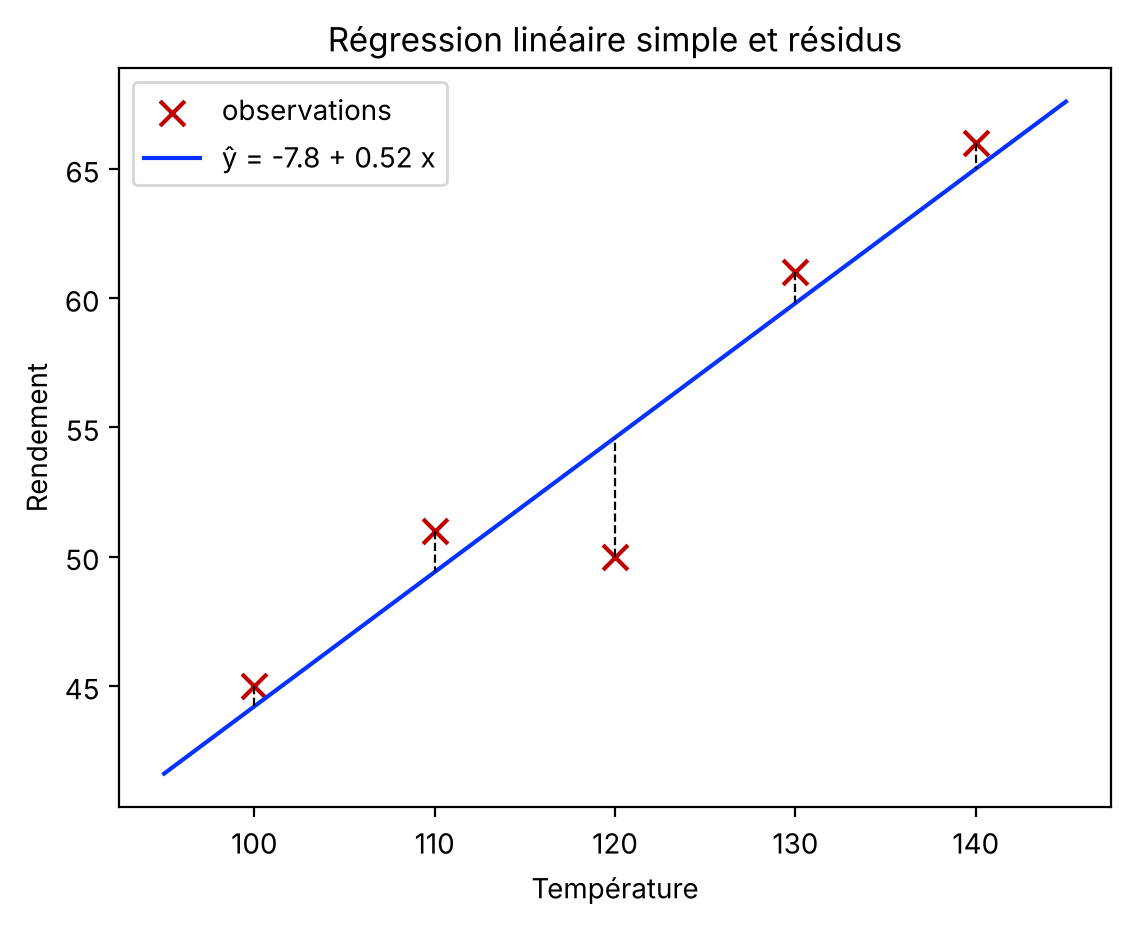

In [8]:
x_ligne = np.linspace(95, 145, 50)
plt.scatter(temperature, rendement, color="#C00000", marker="x", s=80, label="observations")
plt.plot(x_ligne, beta0 + beta1 * x_ligne, color="#0532FF", label="ŷ = -7.8 + 0.52 x")
for xi, yi, pi in zip(temperature, rendement, y_pred):
    plt.plot([xi, xi], [yi, pi], "k--", linewidth=0.8)      # résidus
plt.xlabel("Température"); plt.ylabel("Rendement"); plt.legend()
plt.title("Régression linéaire simple et résidus"); plt.show()

## 5. Descente de gradient pas à pas

*Et si l'on ne connaissait pas la formule ? On peut descendre la pente de l'erreur, pas à pas.*

**Exemple 1 des slides** : les points $(-1,-1)$, $(0,-1)$, $(1,1)$. Solution exacte : $\beta_0=-1/3$, $\beta_1=1$.

On commence par une fonction qui calcule le coût et le gradient :

In [9]:
x1 = np.array([-1, 0, 1], dtype=float)
y1 = np.array([-1, -1, 1], dtype=float)

def cout_et_gradient(b0, b1, x, y):
    """Renvoie L(b0, b1) et les deux dérivées partielles."""
    erreur = (b0 + b1 * x) - y                  # ŷ_i - y_i
    L = np.mean(erreur ** 2)
    g0 = 2 * np.mean(erreur)                    # ∂L/∂β0
    g1 = 2 * np.mean(erreur * x)                # ∂L/∂β1
    return L, g0, g1

Puis la boucle de descente. On affiche les 3 premières itérations, comme dans le tableau des slides :

In [10]:
def descente_gradient(x, y, alpha=0.1, n_iter=200, afficher=3):
    b0, b1 = 0.0, 0.0                           # initialisation
    historique = []
    for it in range(1, n_iter + 1):
        L, g0, g1 = cout_et_gradient(b0, b1, x, y)
        historique.append(L)
        if it <= afficher:
            print(f"it {it}: β0={b0:.3f}  β1={b1:.3f}  L={L:.3f}  grad=({g0:.3f}, {g1:.3f})")
        b0, b1 = b0 - alpha * g0, b1 - alpha * g1   # mise à jour
    return b0, b1, historique

b0_gd, b1_gd, hist = descente_gradient(x1, y1)
print(f"Après 200 itérations : β0 = {b0_gd:.3f}, β1 = {b1_gd:.3f}")

it 1: β0=0.000  β1=0.000  L=1.000  grad=(0.667, -1.333)
it 2: β0=-0.067  β1=0.133  L=0.794  grad=(0.533, -1.156)
it 3: β0=-0.120  β1=0.249  L=0.644  grad=(0.427, -1.001)
Après 200 itérations : β0 = -0.333, β1 = 1.000


La fonction coût diminue à chaque itération :

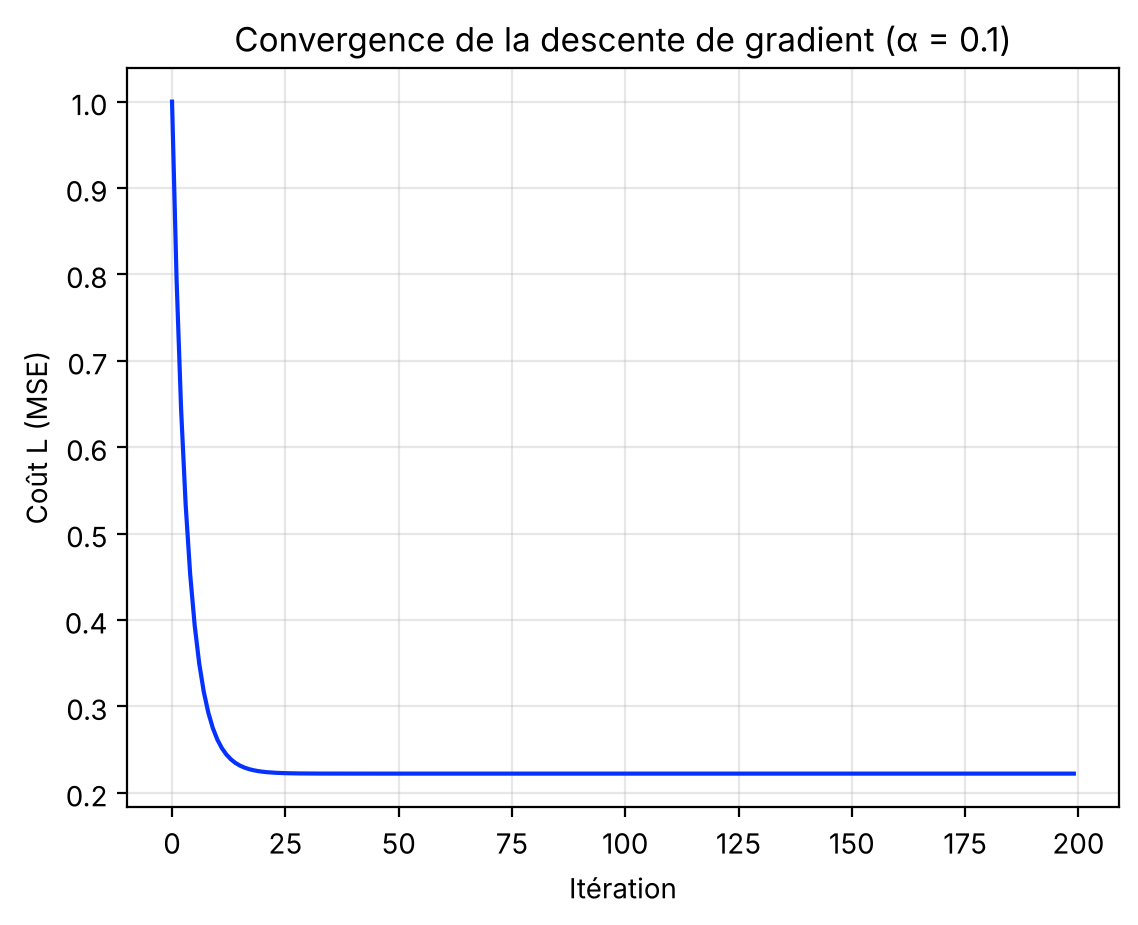

In [11]:
plt.plot(hist, color="#0532FF")
plt.xlabel("Itération"); plt.ylabel("Coût L (MSE)")
plt.title("Convergence de la descente de gradient (α = 0.1)")
plt.grid(alpha=0.3); plt.show()

## 6. Cas pratique : la base Diabetes

*Place aux vraies données : peut-on prédire l'évolution d'un diabète ?*

442 patients, 10 variables (âge, IMC, pression artérielle…) déjà centrées-réduites. Cible : progression de la maladie après un an.

In [12]:
diabete = load_diabetes()
X_diab = pd.DataFrame(diabete.data, columns=diabete.feature_names)
y_diab = diabete.target
print(X_diab.shape)
X_diab.head()

(442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


### 6.1 Régression simple sur l'IMC (`bmi`)

*Une seule variable suffit-elle à bien prédire ?*

On sépare les données : 80 % pour l'apprentissage, 20 % pour le test.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X_diab[["bmi"]], y_diab, test_size=0.2, random_state=42)

modele_simple = LinearRegression().fit(X_train, y_train)
y_pred_test = modele_simple.predict(X_test)
print("β0 =", round(modele_simple.intercept_, 1), "  β1 =", modele_simple.coef_.round(1))
print("MSE test =", round(mean_squared_error(y_test, y_pred_test), 1))
print("R² test  =", round(r2_score(y_test, y_pred_test), 3))

β0 = 152.0   β1 = [998.6]
MSE test = 4061.8
R² test  = 0.233


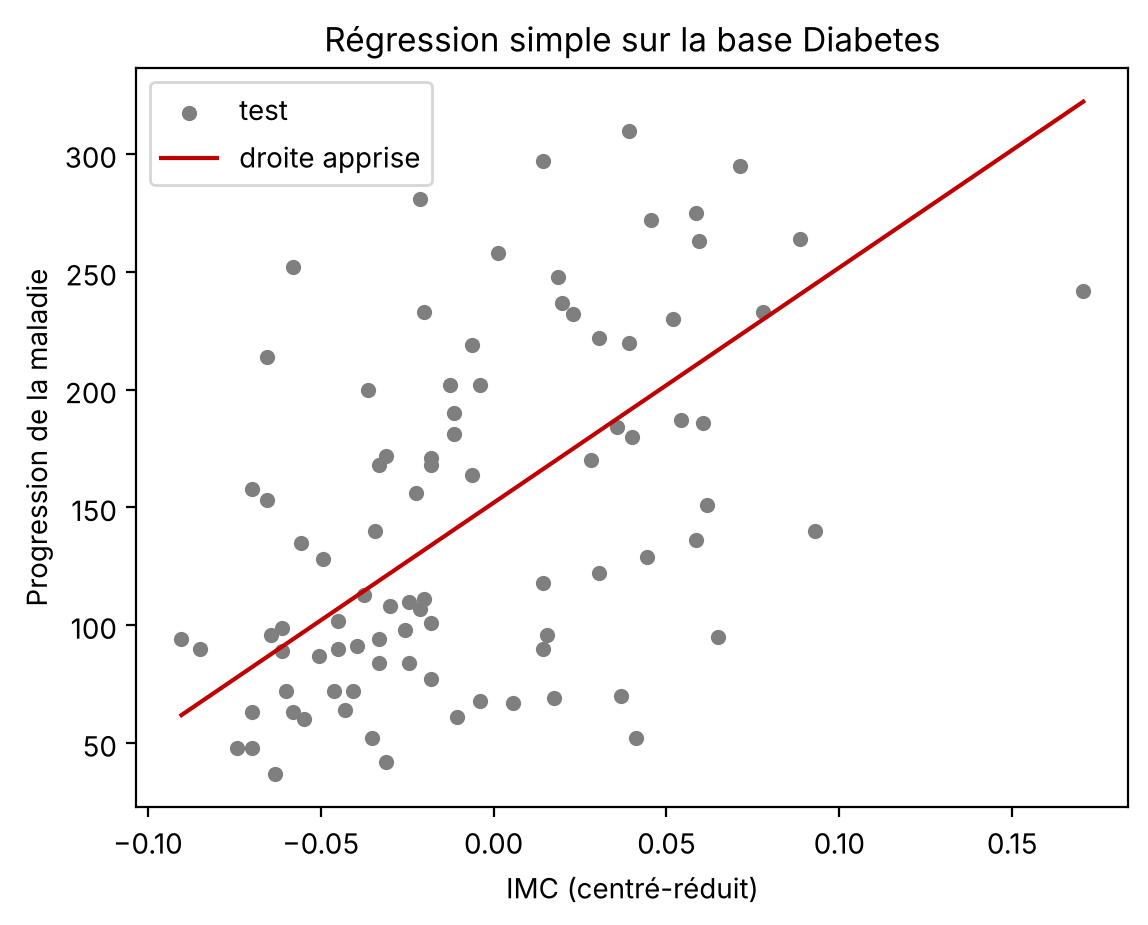

In [14]:
plt.scatter(X_test["bmi"], y_test, s=20, color="#7F7F7F", label="test")
ordre = np.argsort(X_test["bmi"].values)
plt.plot(X_test["bmi"].values[ordre], y_pred_test[ordre], color="#C00000", label="droite apprise")
plt.xlabel("IMC (centré-réduit)"); plt.ylabel("Progression de la maladie")
plt.title("Régression simple sur la base Diabetes"); plt.legend(); plt.show()

### 6.2 Régression multiple (les 10 variables)

*Que gagne-t-on en utilisant les dix variables ?*

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_diab, y_diab, test_size=0.2, random_state=42)

modele_multiple = LinearRegression().fit(X_train, y_train)
y_pred_test = modele_multiple.predict(X_test)
print("MSE test =", round(mean_squared_error(y_test, y_pred_test), 1))
print("R² test  =", round(r2_score(y_test, y_pred_test), 3))
pd.Series(modele_multiple.coef_, index=diabete.feature_names).round(1)

MSE test = 2900.2
R² test  = 0.453


age     37.9
sex   -242.0
bmi    542.4
bp     347.7
s1    -931.5
s2     518.1
s3     163.4
s4     275.3
s5     736.2
s6      48.7
dtype: float64

### 6.3 Évaluation : graphique des résidus

*Les erreurs du modèle cachent-elles une structure ?*

Un bon modèle a des résidus répartis au hasard autour de 0, sans forme particulière.

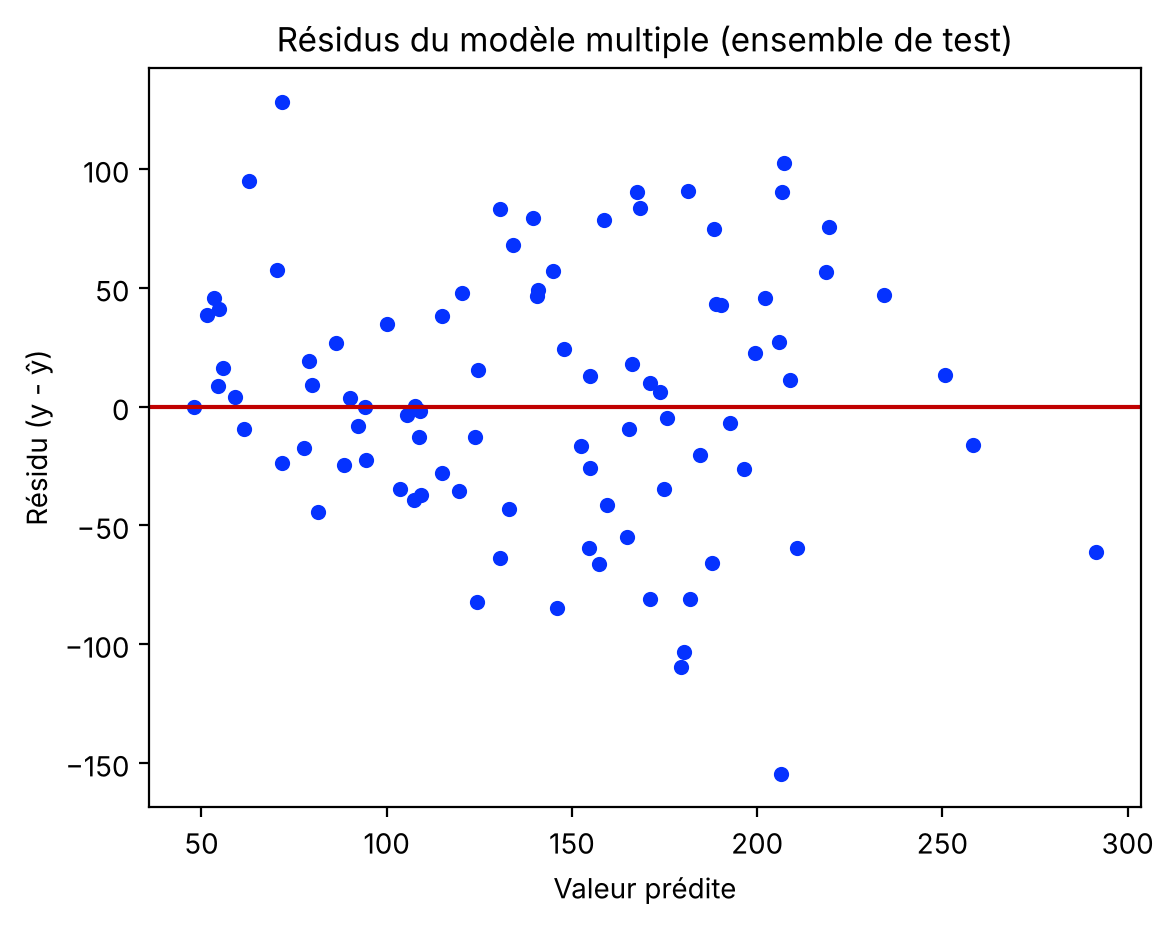

In [16]:
residus_test = y_test - y_pred_test
plt.scatter(y_pred_test, residus_test, s=20, color="#0532FF")
plt.axhline(0, color="#C00000")
plt.xlabel("Valeur prédite"); plt.ylabel("Résidu (y - ŷ)")
plt.title("Résidus du modèle multiple (ensemble de test)"); plt.show()

L'IMC seul explique environ 23 % de la variance ($R^2 \approx 0.23$) ; les 10 variables en expliquent environ 45 %.

## 7. Influence des hyperparamètres

### 7.1 Le pas d'apprentissage $\alpha$

*Quel pas choisir pour descendre la pente ?*

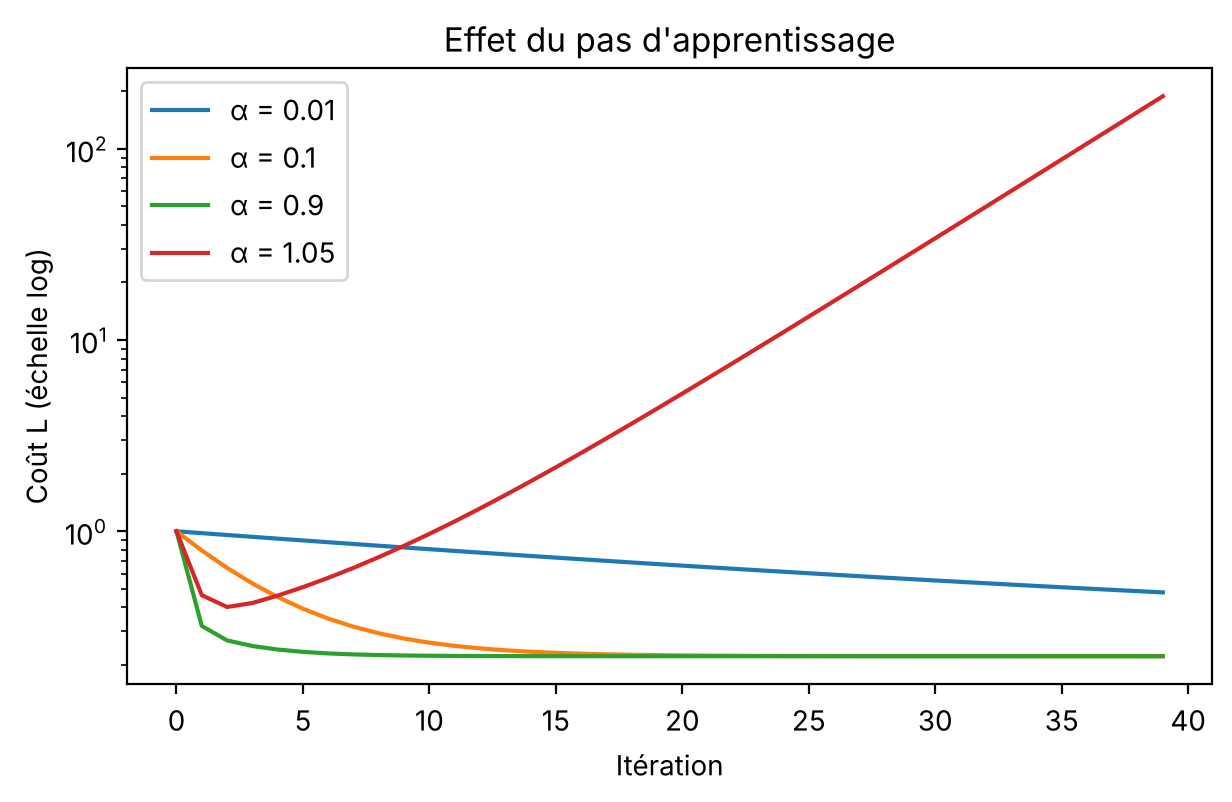

In [17]:
plt.figure(figsize=(7, 4))
for alpha in [0.01, 0.1, 0.9, 1.05]:
    _, _, h = descente_gradient(x1, y1, alpha=alpha, n_iter=40, afficher=0)
    plt.plot(h, label=f"α = {alpha}")
plt.yscale("log"); plt.xlabel("Itération"); plt.ylabel("Coût L (échelle log)")
plt.title("Effet du pas d'apprentissage"); plt.legend(); plt.show()

- $\alpha = 0.01$ : converge **lentement** ;
- $\alpha = 0.1$ : bon compromis ;
- $\alpha = 0.9$ : les paramètres **oscillent** autour de la solution avant de converger ;
- $\alpha = 1.05$ : le pas est trop grand, le coût augmente : l'algorithme **diverge**.

### 7.2 Le degré du polynôme : surapprentissage

*Un modèle plus complexe est-il toujours meilleur ?*

On génère 30 points autour d'une courbe, puis on ajuste des polynômes de degré croissant.

In [18]:
rng = np.random.default_rng(42)
x_poly = np.sort(rng.uniform(-3, 3, 30))
y_poly = 0.5 * x_poly ** 2 - x_poly + rng.normal(0, 1, 30)     # vraie courbe : degré 2
x_tr, x_te, y_tr, y_te = train_test_split(x_poly, y_poly, test_size=0.3, random_state=42)

def mse_polynome(degre):
    poly = PolynomialFeatures(degre)                           # x -> (1, x, x², ...)
    m = LinearRegression().fit(poly.fit_transform(x_tr.reshape(-1, 1)), y_tr)
    erreur = lambda x, y: mean_squared_error(y, m.predict(poly.transform(x.reshape(-1, 1))))
    return erreur(x_tr, y_tr), erreur(x_te, y_te)

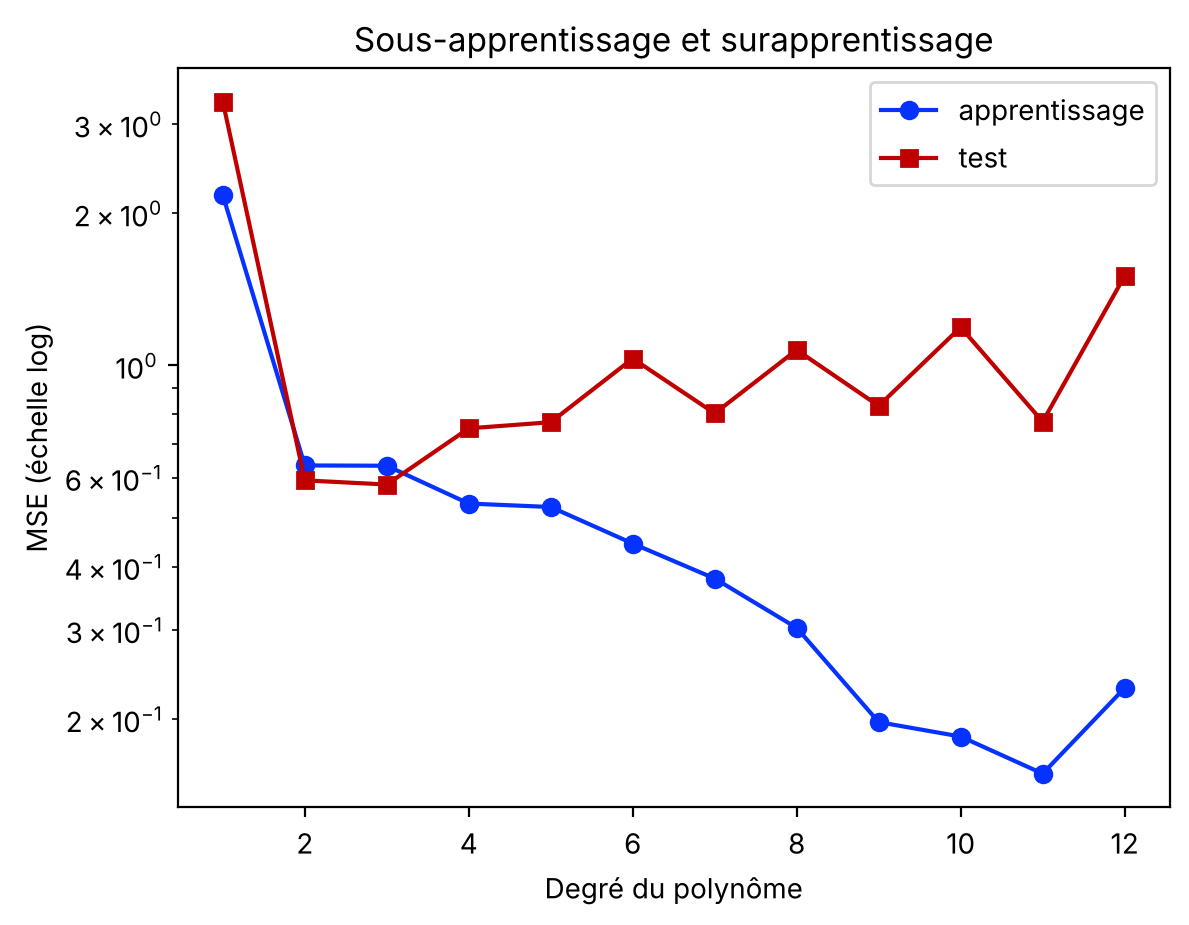

In [19]:
degres = range(1, 13)
erreurs = [mse_polynome(d) for d in degres]
plt.plot(degres, [e[0] for e in erreurs], "o-", color="#0532FF", label="apprentissage")
plt.plot(degres, [e[1] for e in erreurs], "s-", color="#C00000", label="test")
plt.yscale("log"); plt.xlabel("Degré du polynôme"); plt.ylabel("MSE (échelle log)")
plt.title("Sous-apprentissage et surapprentissage"); plt.legend(); plt.show()

L'erreur d'apprentissage diminue globalement quand le degré augmente, mais l'erreur de **test** remonte pour les grands degrés : le modèle apprend le bruit. Le meilleur degré est proche de 2 (la vraie courbe).

## 8. Exercices

*À vous de jouer ! Les exercices sont classés du plus simple au plus exigeant. Essayez de les faire sans regarder les solutions.*

### Exercice 1 (facile) — Moindres carrés sous forme matricielle
Calculez $\hat\beta = (X^TX)^{-1}X^TY$ pour l'exemple température / rendement (n'oubliez pas la colonne de 1 dans $X$). Retrouvez-vous $(-7.8 ; 0.52)$ ?

In [20]:
# À compléter
X_mat = ...

### Exercice 2 (moyen) — Descente de gradient sur la température
Appliquez `descente_gradient` aux données température / rendement **sans les normaliser**. Que se passe-t-il avec $\alpha = 0.1$ ? Normalisez $x$ (centrer-réduire), relancez, puis revenez aux paramètres d'origine.

In [21]:
# À compléter

### Exercice 3 (défi) — Régression multiple « from scratch »
Écrivez une descente de gradient **vectorisée** ($\beta \leftarrow \beta - \alpha \frac{2}{n}X^T(X\beta - Y)$) et appliquez-la à la base Diabetes (10 variables + colonne de 1). Comparez vos coefficients à ceux de `LinearRegression`.

In [22]:
# À compléter

## 9. Solutions

*Comparez vos réponses avec les propositions ci-dessous ; il existe souvent plusieurs façons correctes de faire.*

<details>
<summary><b>Solution de l'exercice 1</b> (cliquer pour afficher)</summary>

```python
X_mat = np.column_stack([np.ones(n), temperature])     # colonne de 1 pour β0
beta = np.linalg.inv(X_mat.T @ X_mat) @ X_mat.T @ rendement
print(beta)    # [-7.8   0.52]
```
</details>

<details>
<summary><b>Solution de l'exercice 2</b> (cliquer pour afficher)</summary>

```python
descente_gradient(temperature, rendement, alpha=0.1, n_iter=5)   # les valeurs explosent : divergence
x_norm = (temperature - temperature.mean()) / temperature.std()  # centrer-réduire
b0_n, b1_n, _ = descente_gradient(x_norm, rendement, alpha=0.1, n_iter=500, afficher=0)
b1 = b1_n / temperature.std()                                    # retour à l'échelle d'origine
b0 = b0_n - b1 * temperature.mean()
print(round(b0, 2), round(b1, 2))   # -7.8  0.52
```
Avec des $x$ de l'ordre de 100, le gradient est énorme et $\alpha = 0.1$ fait diverger l'algorithme. La normalisation met toutes les variables à la même échelle.
</details>

<details>
<summary><b>Solution de l'exercice 3</b> (cliquer pour afficher)</summary>

```python
X_full = np.column_stack([np.ones(len(X_diab)), X_diab.values])
beta = np.zeros(X_full.shape[1])
for _ in range(20000):
    gradient = 2 / len(y_diab) * X_full.T @ (X_full @ beta - y_diab)
    beta -= 0.5 * gradient
ref = LinearRegression().fit(X_diab, y_diab)
print(beta[:3].round(1), ref.intercept_.round(1), ref.coef_[:2].round(1))
```
Les coefficients se rapprochent de ceux de scikit-learn ; la convergence est lente car certaines variables sont corrélées.
</details>

## 10. Conclusion — ce qu'il faut retenir

*Avant de passer à la suite, prenons une minute pour résumer l'essentiel.*

- Les moindres carrés donnent une **formule exacte** pour $\beta_0$ et $\beta_1$ (ou $\hat\beta = (X^TX)^{-1}X^TY$).
- La **descente de gradient** atteint la même solution ; le pas $\alpha$ et la **normalisation** des variables sont essentiels.
- On évalue sur un **ensemble de test** avec la **MSE** et le **$R^2$**.
- Un modèle trop complexe (degré élevé) **surapprend** : l'erreur de test remonte.

➡️ Prochain cours : KNN, sur les mêmes 6 fleurs que les cours de clustering.